## Part A

### Prepare

In [1]:
#import lib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import load_iris

In [2]:
#load the dataset
iris = load_iris(as_frame=True)
data = iris.data

In [3]:
#select two numerical features
X = data["petal length (cm)"]
Y = data["petal width (cm)"]

print("Number of samples:", len(data))
print(data[["petal length (cm)", "petal width (cm)"]].head())

Number of samples: 150
   petal length (cm)  petal width (cm)
0                1.4               0.2
1                1.4               0.2
2                1.3               0.2
3                1.5               0.2
4                1.4               0.2


### Implement

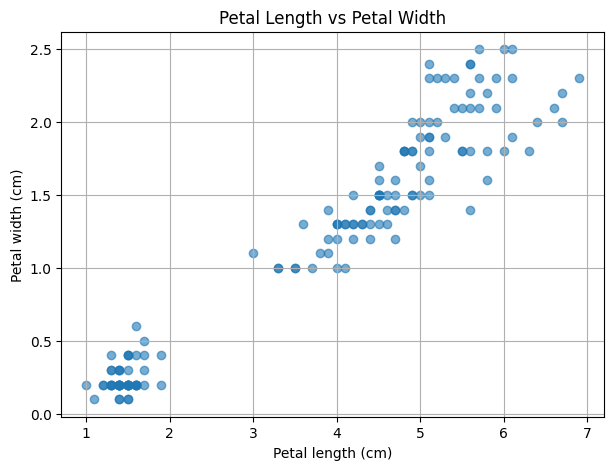

Correlation: 0.9628654314027961


In [4]:
plt.figure(figsize=(7, 5))

plt.scatter(X, Y, alpha=0.6)

plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Petal Length vs Petal Width")
plt.grid(True)

plt.show()

print("Correlation:", X.corr(Y))

In [5]:
labels = ["Low", "Medium", "High"]

#discretize X and Y into 3 quantile-based categories
X_category = pd.qcut(X, q=3, labels=labels)
Y_category = pd.qcut(Y, q=3, labels=labels)

print("X categories:")
print(X_category.value_counts().sort_index())

print("\nY categories:")
print(Y_category.value_counts().sort_index())

X categories:
petal length (cm)
Low       50
Medium    54
High      46
Name: count, dtype: int64

Y categories:
petal width (cm)
Low       50
Medium    52
High      48
Name: count, dtype: int64


In [6]:
#construct the joint frequency table
frequency_table = pd.crosstab(
    X_category,
    Y_category
)

print(frequency_table)

petal width (cm)   Low  Medium  High
petal length (cm)                   
Low                 50       0     0
Medium               0      47     7
High                 0       5    41


In [7]:
#calculate joint probability distribution
joint_probability = frequency_table / len(data)

print(joint_probability)

#verify that all probabilities sum to 1
print("\nTotal probability:")
print(joint_probability.values.sum())

petal width (cm)        Low    Medium      High
petal length (cm)                              
Low                0.333333  0.000000  0.000000
Medium             0.000000  0.313333  0.046667
High               0.000000  0.033333  0.273333

Total probability:
1.0


In [8]:
#calculate marginal distributions
p_X = joint_probability.sum(axis=1)
p_Y = joint_probability.sum(axis=0)

print("Marginal distribution of X:")
print(p_X)

print("\nMarginal distribution of Y:")
print(p_Y)

Marginal distribution of X:
petal length (cm)
Low       0.333333
Medium    0.360000
High      0.306667
dtype: float64

Marginal distribution of Y:
petal width (cm)
Low       0.333333
Medium    0.346667
High      0.320000
dtype: float64


In [9]:
#conditional distribution p(Y | X)
p_Y_given_X = frequency_table.div(
    frequency_table.sum(axis=1),
    axis=0
)

#conditional distribution p(X | Y)
p_X_given_Y = frequency_table.div(
    frequency_table.sum(axis=0),
    axis=1
)

print("P(Y | X):")
print(p_Y_given_X)

print("\nP(X | Y):")
print(p_X_given_Y)

P(Y | X):
petal width (cm)   Low    Medium      High
petal length (cm)                         
Low                1.0  0.000000  0.000000
Medium             0.0  0.870370  0.129630
High               0.0  0.108696  0.891304

P(X | Y):
petal width (cm)   Low    Medium      High
petal length (cm)                         
Low                1.0  0.000000  0.000000
Medium             0.0  0.903846  0.145833
High               0.0  0.096154  0.854167


In [10]:
#calculate expected joint probabilities under independence
independent_probability = np.outer(
    p_X.values,
    p_Y.values
)

independent_table = pd.DataFrame(
    independent_probability,
    index=labels,
    columns=labels
)

print("Observed joint probability:")
print(joint_probability)

print("\nExpected joint probability if independent:")
print(independent_table)

print("\nDifference:")
print(joint_probability - independent_table)

Observed joint probability:
petal width (cm)        Low    Medium      High
petal length (cm)                              
Low                0.333333  0.000000  0.000000
Medium             0.000000  0.313333  0.046667
High               0.000000  0.033333  0.273333

Expected joint probability if independent:
             Low    Medium      High
Low     0.111111  0.115556  0.106667
Medium  0.120000  0.124800  0.115200
High    0.102222  0.106311  0.098133

Difference:
petal width (cm)        Low    Medium      High
petal length (cm)                              
Low                0.222222 -0.115556 -0.106667
Medium            -0.120000  0.188533 -0.068533
High              -0.102222 -0.072978  0.175200
